In [90]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv


In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

In [92]:
df = pd.read_csv('/kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv')
print(df.head())
print(df.info())
print(df.shape)
print(df.isnull().sum())
print(df.describe())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
(200, 5)
CustomerID                0
Gender        

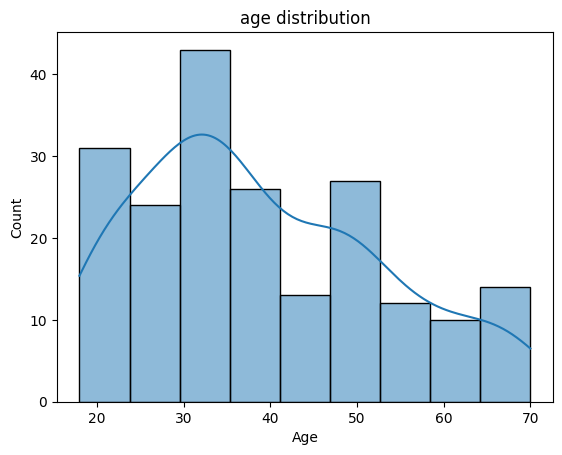

In [93]:
##univariate analysis
plt.title('age distribution')
sns.histplot(data = df,x = df['Age'],kde = True)
plt.show()


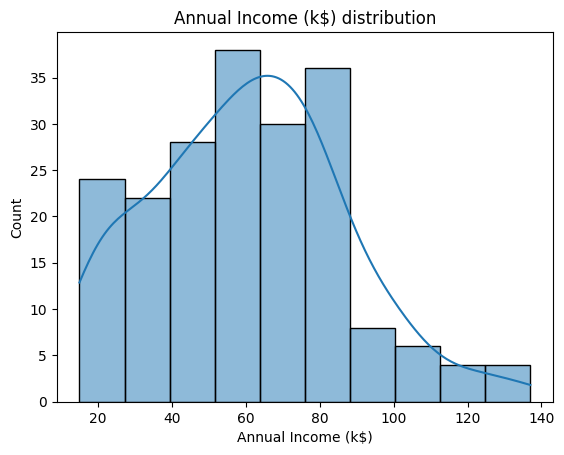

In [94]:
##univariate analysis
plt.title('Annual Income (k$) distribution')
sns.histplot(data = df,x = df['Annual Income (k$)'],kde = True)
plt.show()


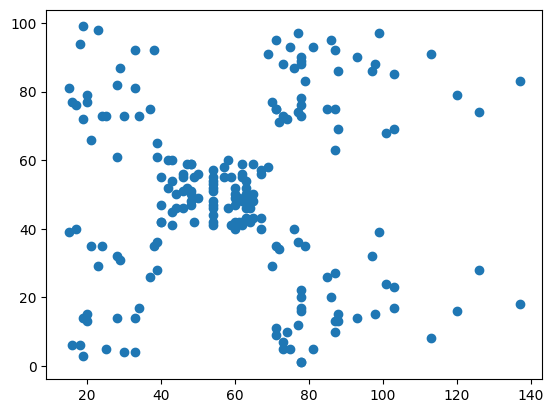

In [95]:
#bivariate analysis
plt.scatter(data = df,x = 'Annual Income (k$)',y ='Spending Score (1-100)' )
plt.show()

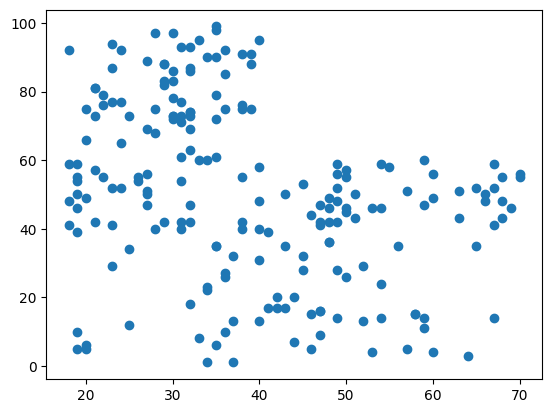

In [96]:
plt.scatter(data = df,x = 'Age',y ='Spending Score (1-100)' )
plt.show()

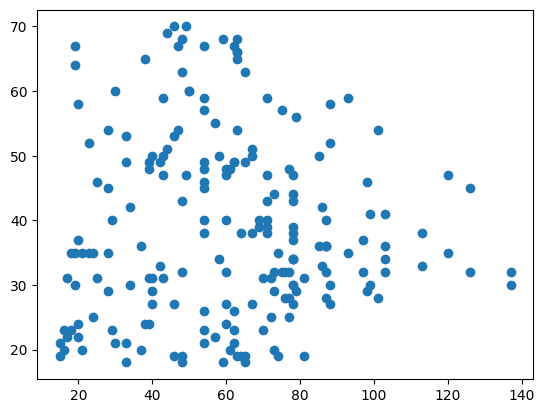

In [97]:
plt.scatter(data = df,x = 'Annual Income (k$)',y ='Age' )
plt.show()

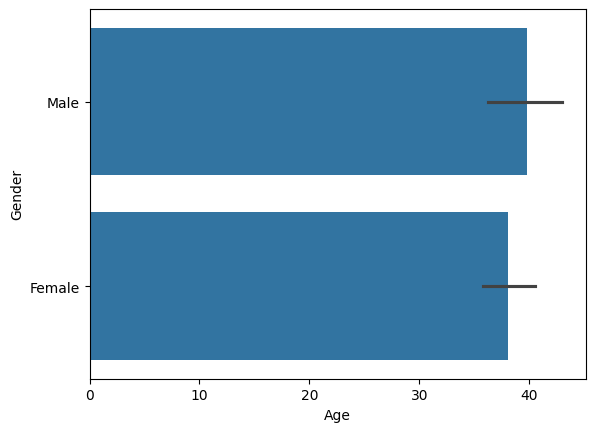

In [98]:
sns.barplot(data=df,x='Age',y='Gender')
plt.show()

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


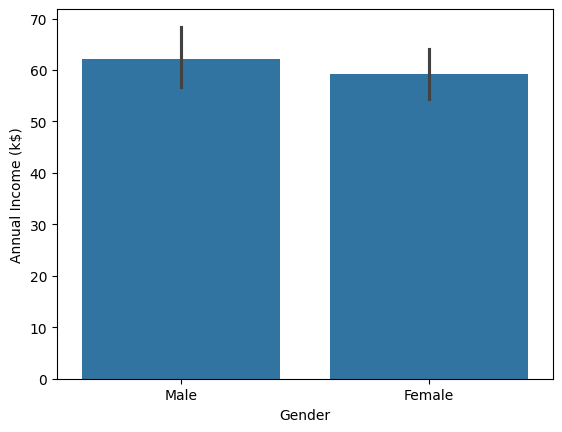

In [100]:
sns.barplot(data=df,x='Gender',y='Annual Income (k$)')
plt.show()

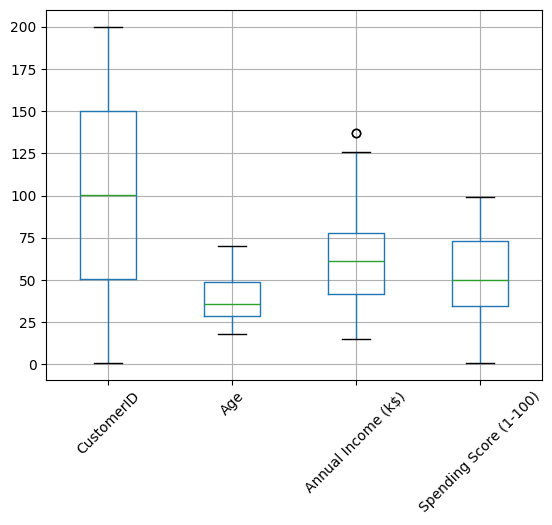

In [101]:
df.boxplot()
plt.xticks(rotation=45)
plt.show()

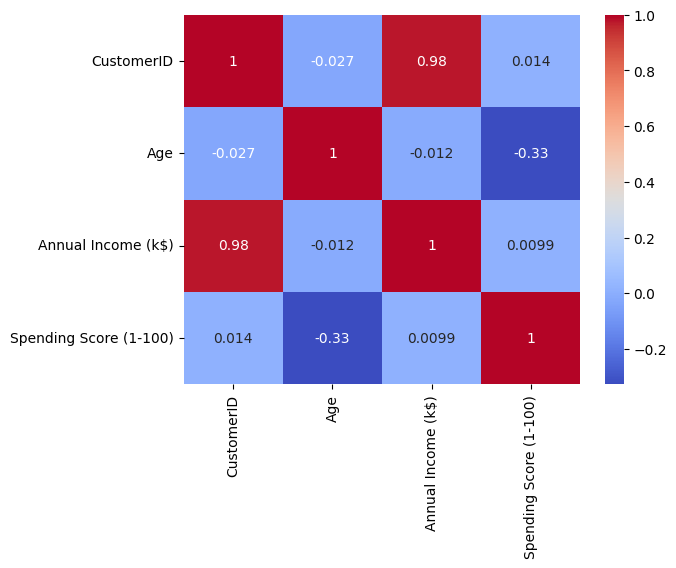

In [102]:
corr =df.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

In [103]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [104]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [118]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline



In [127]:
notimpcol = ['CustomerID','Gender']
df = df.drop(columns=notimpcol)





KeyError: "['CustomerID', 'Gender'] not found in axis"

In [128]:
df

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40
...,...,...,...
195,35,120,79
196,45,126,28
197,32,126,74
198,32,137,18


In [132]:
from sklearn.preprocessing import StandardScaler
dfsc = StandardScaler().fit_transform(df)

dfsc = pd.DataFrame(dfsc,columns = df.columns,index=df.index)


,Age,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01
50%,-2.045351e-01,3.587926e-02,-7.764312e-03
75%,7.284319e-01,6.656748e-01,8.851316e-01
max,2.235532e+00,2.917671e+00,1.894492e+00


In [115]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [135]:
kmeans = KMeans(n_clusters=3,random_state = 42,n_init = 20)
labels = kmeans.fit_predict(dfsc)
print(labels)

[2 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5
 2 5 2 1 2 5 2 5 2 1 4 4 4 1 4 4 1 1 1 1 1 4 1 1 4 1 1 1 4 1 1 4 4 1 1 1 1
 1 4 1 4 4 1 1 4 1 1 4 1 1 4 4 1 1 4 1 4 4 4 1 4 1 4 4 1 1 4 1 4 1 1 1 1 1
 4 4 4 4 4 1 1 1 1 4 4 4 3 4 3 0 3 0 3 0 3 4 3 0 3 0 3 4 3 0 3 4 3 0 3 0 3
 0 3 0 3 0 3 0 3 0 3 0 3 1 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3 0
 3 0 3 0 3 0 3 0 3 0 3 0 3 0 3]


In [138]:
silhouette_scores = []
center_range = range(2,15)
for i in center_range:
    kmeans = KMeans(n_clusters=i,random_state=1,n_init=20)
    labels = kmeans.fit_predict(dfsc)
    score = silhouette_score(dfsc,labels)
    silhouette_scores.append(score)
print("center & their silhouette_score")
for k, score in zip(center_range,silhouette_scores):
    print(f"K = {k} : silhouette_score = {score:.2f}")

center & their silhouette_score
K = 2 : silhouette_score = 0.34
K = 3 : silhouette_score = 0.36
K = 4 : silhouette_score = 0.40
K = 5 : silhouette_score = 0.42
K = 6 : silhouette_score = 0.43
K = 7 : silhouette_score = 0.42
K = 8 : silhouette_score = 0.41
K = 9 : silhouette_score = 0.42
K = 10 : silhouette_score = 0.40
K = 11 : silhouette_score = 0.41
K = 12 : silhouette_score = 0.39
K = 13 : silhouette_score = 0.39
K = 14 : silhouette_score = 0.38


In [143]:
kmeans = KMeans(n_clusters=6,random_state = 42,n_init = 20)
labels = kmeans.fit_predict(dfsc)
df['labels']=labels
print(df.head())

   Age  Annual Income (k$)  Spending Score (1-100)  labels
0   19                  15                      39       2
1   21                  15                      81       2
2   20                  16                       6       5
3   23                  16                      77       2
4   31                  17                      40       5
